*Robot Motion Control · Chapter 7 — Optimal, Predictive and Learning-Based Control*

# 7.1 Linear-Quadratic Regulation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/RMC/07-optimal-predictive-and-learning-control/7.1-linear-quadratic-regulation.ipynb)

Pole placement lets us choose where the closed-loop poles go, but it does not say *which* poles are good, and for a
robot with several joints the choice is far from obvious. **Optimal control** replaces the question with a cost:
penalise the deviation of the state and the effort of the actuators, and let mathematics find the feedback that
minimises the total. For linear dynamics and a quadratic cost the answer is the **linear-quadratic regulator (LQR)**,
a single matrix of gains obtained from the solution of a Riccati equation. This notebook derives the equation by
dynamic programming, explains how to choose the weights, states the (remarkable) robustness guarantees, extends
the regulator to set-points, disturbances and integral action, and then applies it to real robot models in MuJoCo
— a Dynamixel 2R arm held in an *unstable* posture and a six-joint UR5e holding a payload.

| | |
|:--|:--|
| **Primary reading** | [R. Tedrake, *Underactuated Robotics* (MIT, free online)](https://underactuated.mit.edu/) — the chapters on dynamic programming and on linear quadratic regulation · Ogata, *Modern Control Engineering*, the state-space design chapters (quadratic optimal regulator) |
| **Parallel reading** | [CMU 16-745 *Optimal Control and Reinforcement Learning*, lecture notes](https://optimalcontrol.ri.cmu.edu/) (dynamic programming, LQR) · Lynch and Park, *Modern Robotics*, Ch. 11 (the robot models we regulate) · Spong et al., Part III (control of manipulators) |
| **Lectures** | [S. Brunton, *Control Bootcamp* (overview video)](https://www.youtube.com/watch?v=Pi7l8mMjYVE) · [MIT *Underactuated Robotics* (R. Tedrake), example lecture](https://www.youtube.com/watch?v=pZ5-yS4X0wg) |
| **Prerequisites** | Chapter 1 (state-space models, pole placement) · Chapter 2 (the single-joint model) · linear algebra and the matrix exponential ([math primer](../../math-primer/README.md)) |
| **Study time** | about 3 hours |

## Learning objectives

1. Formulate a regulation task as a linear-quadratic (LQ) optimal-control problem and interpret the weights $Q$, $R$ and $Q_f$.
2. Derive the discrete-time Riccati recursion by dynamic programming and the continuous-time algebraic Riccati equation (ARE) from the Hamilton–Jacobi–Bellman equation, and compute the gain with `numpy`/`scipy`.
3. Choose $Q$ and $R$ with Bryson's rule, predict how the closed-loop poles move as $R$ varies, and read the trade-off between state error and control effort from a Pareto curve.
4. State and verify the guaranteed margins of continuous-time LQR (return-difference inequality, gain margin $(\tfrac12,\infty)$, phase margin $\ge 60^\circ$).
5. Extend the regulator to a non-zero equilibrium, to reference tracking and to a constant disturbance by adding integral action.
6. Linearise a MuJoCo robot with `mjd_transitionFD`, confirm the result against a hand derivation, and use LQR to hold an open-loop-unstable posture of a 2R arm and a six-joint UR5e.

## Contents

1. [From pole placement to a cost](#1.-From-pole-placement-to-a-cost)
2. [Dynamic programming and the Riccati recursion](#2.-Dynamic-programming-and-the-Riccati-recursion)
3. [The infinite-horizon problem and the algebraic Riccati equation](#3.-The-infinite-horizon-problem-and-the-algebraic-Riccati-equation)
4. [Choosing Q and R](#4.-Choosing-Q-and-R)
5. [Why LQR is robust](#5.-Why-LQR-is-robust)
6. [Set-points, tracking and integral action](#6.-Set-points,-tracking-and-integral-action)
7. [LQR on real robots in MuJoCo](#7.-LQR-on-real-robots-in-MuJoCo)
8. [Worked examples](#8.-Worked-examples)
9. [Summary, common mistakes and exercises](#9.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

import scipy.linalg as sla
from rgkit import optimal_control as oc, mj_control as mc, mujoco_utils as mju, robots
import mujoco
np.set_printoptions(precision=4, suppress=True, linewidth=110)

## 1. From pole placement to a cost

Consider a plant $\dot{\mathbf x} = A\mathbf x + B\mathbf u$ that we want to bring to the origin. With state feedback
$\mathbf u = -K\mathbf x$ the closed-loop poles are the eigenvalues of $A - BK$, and pole placement can put them
anywhere if $(A,B)$ is controllable. Placing them far to the left gives a fast response, but at the price of large
control signals, which a real actuator can neither supply nor tolerate; placing them near the origin is gentle but slow.
For a single input the engineer can iterate by hand. For a robot with six actuators and twelve states, the number of
free parameters in $K$ is $6\times12=72$, and nothing in the pole locations tells us how the joints should share the
effort. We need a *criterion*.

The criterion adopted here is the **quadratic cost**

$$
J = \int_0^{\infty}\Big(\mathbf x^{\mathsf T}Q\,\mathbf x + \mathbf u^{\mathsf T}R\,\mathbf u\Big)\,dt,
\qquad Q = Q^{\mathsf T}\succeq 0,\quad R = R^{\mathsf T}\succ 0 .
$$

The first term penalises the distance of the state from the target, measured in the metric $Q$; the second
penalises the actuator effort, in the metric $R$ (for a motor, $\mathbf u^{\mathsf T}R\mathbf u$ is proportional to
the electrical power if $R$ is diagonal and $\mathbf u$ is the torque). The two terms compete: shrinking the
error quickly requires effort. The **linear-quadratic regulator** is the feedback law that minimises $J$ for linear
dynamics. (Quadratic costs are not the only sensible choice, but they are the one for which the problem has a
closed-form solution, and — as Sections 5 and 7 show — a solution that is useful even when the plant is not exactly linear.)

We shall use the inverted pendulum as a running example, because its upright position is the simplest unstable
equilibrium. Let $\theta$ be measured from the *hanging* position, so that the upright position is $\theta=\pi$, and let
the pendulum have mass $m$, length $\ell$ and viscous damping $b$:

$$
m\ell^2\ddot\theta = u - m g\ell\sin\theta - b\dot\theta .
$$

With $\varphi=\theta-\pi$ the deviation from the upright position, $\sin\theta=-\sin\varphi\approx-\varphi$, so that
$\ddot\varphi \approx (g/\ell)\varphi - (b/m\ell^2)\dot\varphi + u/m\ell^2$. In the state $\mathbf x=(\varphi,\dot\varphi)$,

$$
A = \begin{bmatrix}0 & 1\\ g/\ell & -b/(m\ell^2)\end{bmatrix},\qquad
B = \begin{bmatrix}0\\ 1/(m\ell^2)\end{bmatrix}.
$$

The characteristic polynomial $s^2 + (b/m\ell^2)s - g/\ell$ has one root in the right half-plane: the plant is unstable
without feedback. We take $m=\ell=1$ (so $m\ell^2 = 1\ \mathrm{kg\,m^2}$), $b = 0.1$ and $g=9.81$, and obtain $A$ and $B$ numerically
by central differences of the full nonlinear model (`oc.linearize`), which will also be the method for MuJoCo in Section 7.

In [2]:
g, ell, mass, damp = 9.81, 1.0, 1.0, 0.1

def pend_f(x, u):
    """Continuous-time pendulum, theta measured from the hanging position: x = (theta, omega)."""
    return np.array([x[1], (u[0] - mass * g * ell * np.sin(x[0]) - damp * x[1]) / (mass * ell ** 2)])

x_up = np.array([np.pi, 0.0])                                  # upright equilibrium, u = 0
A_c, B_c = oc.linearize(pend_f, x_up, [0.0])
display(Math(matrix_to_latex(A_c, 3, "A") + r"\qquad" + matrix_to_latex(B_c, 3, "B")))
print("open-loop poles:", np.linalg.eigvals(A_c).round(4), "  -> one unstable pole")
print("controllable:", np.linalg.matrix_rank(oc.controllability_matrix(A_c, B_c)) == 2)

<IPython.core.display.Math object>

open-loop poles: [ 3.0825+0.j -3.1825+0.j]   -> one unstable pole
controllable: True


## 2. Dynamic programming and the Riccati recursion

We derive the solution in discrete time, where the argument is elementary and also shows *why* the answer is a
feedback law. Let the plant be $\mathbf x_{k+1}=A\mathbf x_k + B\mathbf u_k$ and the finite-horizon cost

$$
J = \sum_{k=0}^{N-1}\big(\mathbf x_k^{\mathsf T}Q\mathbf x_k + \mathbf u_k^{\mathsf T}R\mathbf u_k\big) + \mathbf x_N^{\mathsf T}Q_f\mathbf x_N .
$$

**The principle of optimality.** Let $V_k(\mathbf x)$ be the smallest cost that can still be incurred from time $k$
onward, starting in state $\mathbf x$ — the *cost-to-go* or *value function*. A tail of an optimal trajectory is
itself optimal for the tail problem, which gives Bellman's recursion

$$
V_N(\mathbf x) = \mathbf x^{\mathsf T}Q_f\mathbf x,\qquad
V_k(\mathbf x) = \min_{\mathbf u}\Big[\mathbf x^{\mathsf T}Q\mathbf x + \mathbf u^{\mathsf T}R\mathbf u + V_{k+1}(A\mathbf x + B\mathbf u)\Big].
$$

**The quadratic ansatz.** Suppose $V_{k+1}(\mathbf x)=\mathbf x^{\mathsf T}P_{k+1}\mathbf x$ with $P_{k+1}\succeq0$ (true for
$k+1=N$ with $P_N=Q_f$). The bracket is then a quadratic function of $\mathbf u$,

$$
\mathbf x^{\mathsf T}(Q + A^{\mathsf T}P_{k+1}A)\mathbf x + 2\mathbf u^{\mathsf T}B^{\mathsf T}P_{k+1}A\mathbf x
+ \mathbf u^{\mathsf T}(R + B^{\mathsf T}P_{k+1}B)\mathbf u ,
$$

with a positive-definite Hessian because $R\succ0$. Setting its gradient with respect to $\mathbf u$ to zero gives the
minimiser, and substituting it back gives the minimum:

> **Riccati recursion (discrete time).**
> $$
> K_k = \big(R + B^{\mathsf T}P_{k+1}B\big)^{-1}B^{\mathsf T}P_{k+1}A,\qquad \mathbf u_k^\star = -K_k\mathbf x_k,
> $$
> $$
> P_k = Q + A^{\mathsf T}P_{k+1}A - A^{\mathsf T}P_{k+1}B\big(R + B^{\mathsf T}P_{k+1}B\big)^{-1}B^{\mathsf T}P_{k+1}A,\qquad P_N=Q_f .
> $$

Three consequences deserve emphasis. (i) The optimal input is a **linear state feedback** — we assumed nothing of the
kind; it emerges. (ii) The recursion runs **backwards** from the terminal cost, so the gains are computed offline and
are *time-varying*: $K_0, K_1,\dots,K_{N-1}$. (iii) The minimum cost from $\mathbf x_0$ is $\mathbf x_0^{\mathsf T}P_0\mathbf x_0$,
available without simulating anything.

The cell below tests the claim on a random three-state, two-input system by minimising $J$ directly over all
$2N$ input values with a general-purpose optimiser (BFGS), and compares with $\mathbf x_0^{\mathsf T}P_0\mathbf x_0$.

In [3]:
rng = np.random.default_rng(3)
A3, B3 = rng.normal(size=(3, 3)) * 0.6, rng.normal(size=(3, 2))
Q3, R3, Qf3, N3 = np.eye(3), 0.5 * np.eye(2), 3 * np.eye(3), 6
x03 = np.array([1.0, -2.0, 0.5])

def cost_of_inputs(Uflat):
    U, x, J = Uflat.reshape(N3, 2), x03.copy(), 0.0
    for k in range(N3):
        J += x @ Q3 @ x + U[k] @ R3 @ U[k]
        x = A3 @ x + B3 @ U[k]
    return J + x @ Qf3 @ x

from scipy.optimize import minimize
brute = minimize(cost_of_inputs, np.zeros(2 * N3), method="BFGS", options=dict(gtol=1e-10))
K_list, P_list = oc.riccati_recursion(A3, B3, Q3, R3, Qf3, N3)
print(f"direct minimisation over {2 * N3} variables : J = {brute.fun:.8f}")
print(f"dynamic programming  x0' P0 x0           : J = {x03 @ P_list[0] @ x03:.8f}")
# closed-loop rollout with the time-varying gains reproduces the same inputs
x, U_dp = x03.copy(), []
for k in range(N3):
    U_dp.append(-K_list[k] @ x); x = A3 @ x + B3 @ U_dp[-1]
print("inputs from the feedback law agree with the brute-force optimum:", np.allclose(np.ravel(U_dp), brute.x, atol=1e-5))

direct minimisation over 12 variables : J = 6.65599625
dynamic programming  x0' P0 x0           : J = 6.65599625
inputs from the feedback law agree with the brute-force optimum: True


The figure below shows the gains of the double integrator $\ddot y = u$ sampled at $\Delta t=0.1\ \mathrm{s}$ (a point mass
pushed along a line, or one robot joint with the inertia scaled out). Reading the backward recursion from right to left:
near the end of the horizon the gain depends on the terminal weight $Q_f$ — the controller "knows" that the game is
about to end — but far from the end it settles to a constant. The constant is the solution of the *stationary*
Riccati equation, the subject of the next section.

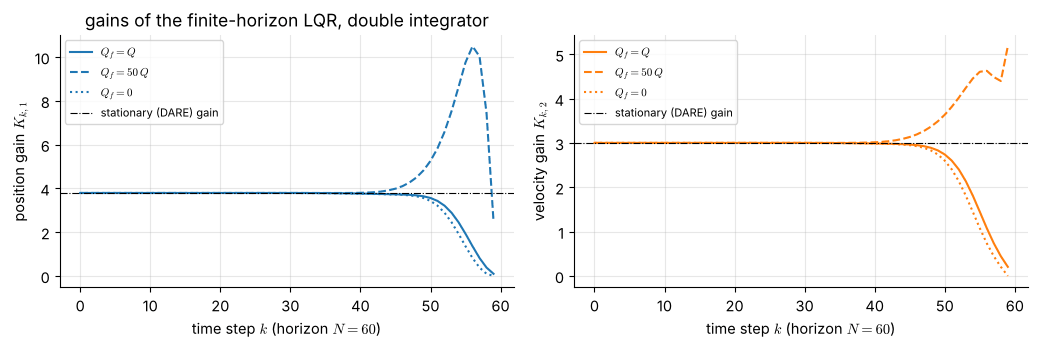

stationary gain K = [[3.7911 3.0032]]   P =
 [[7.9218 2.2417]
 [2.2417 1.7137]]


In [4]:
Ad, Bd = oc.c2d(np.array([[0, 1.0], [0, 0]]), np.array([[0.0], [1.0]]), 0.1)
Qd, Rd, N = np.diag([1.0, 0.1]), np.array([[0.05]]), 60
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
for Qf, ls, lab in [(Qd, "-", r"$Q_f=Q$"), (np.diag([50.0, 5.0]), "--", r"$Q_f=50\,Q$"), (np.zeros((2, 2)), ":", r"$Q_f=0$")]:
    K, P = oc.riccati_recursion(Ad, Bd, Qd, Rd, Qf, N)
    K = np.array(K)[:, 0, :]
    axs[0].plot(K[:, 0], ls, color="C0", label=lab); axs[1].plot(K[:, 1], ls, color="C1", label=lab)
Kinf, Pinf = oc.dlqr(Ad, Bd, Qd, Rd)
for ax, i, name in zip(axs, (0, 1), ("position gain $K_{k,1}$", "velocity gain $K_{k,2}$")):
    ax.axhline(Kinf[0, i], color="k", lw=0.8, ls="-.", label="stationary (DARE) gain")
    ax.set_xlabel("time step $k$ (horizon $N=60$)"); ax.set_ylabel(name); ax.legend(fontsize=8)
axs[0].set_title("gains of the finite-horizon LQR, double integrator")
plt.tight_layout(); plt.show()
print("stationary gain K =", Kinf.round(4), "  P =\n", Pinf.round(4))

## 3. The infinite-horizon problem and the algebraic Riccati equation

For a regulator that must run indefinitely we let $N\to\infty$. If $(A,B)$ is **stabilisable** and $(Q^{1/2},A)$ is
**detectable** (so that every unstable mode is both controllable and visible in the cost), $P_k$ converges to a unique
positive-semidefinite $P$ that satisfies the **discrete algebraic Riccati equation (DARE)**, i.e. the recursion above
with $P_k=P_{k+1}=P$, and the stationary gain $K=(R+B^{\mathsf T}PB)^{-1}B^{\mathsf T}PA$ renders $A-BK$ stable. The
feedback is then time-invariant — the form used on robots.

**Continuous time.** Replacing the sum by an integral, the value function satisfies the *Hamilton–Jacobi–Bellman*
equation

$$
0 = \min_{\mathbf u}\Big[\mathbf x^{\mathsf T}Q\mathbf x + \mathbf u^{\mathsf T}R\mathbf u
+ \nabla V(\mathbf x)^{\mathsf T}(A\mathbf x + B\mathbf u)\Big],
$$

which says that the cost incurred per unit time plus the rate of change of the cost-to-go must vanish along an
optimal path. Trying $V(\mathbf x)=\mathbf x^{\mathsf T}P\mathbf x$, so $\nabla V = 2P\mathbf x$, the minimiser is
$\mathbf u^\star = -R^{-1}B^{\mathsf T}P\mathbf x$ and the equation reduces to the **continuous algebraic Riccati equation (CARE)**

$$
\boxed{\,A^{\mathsf T}P + PA - PBR^{-1}B^{\mathsf T}P + Q = 0,\qquad K = R^{-1}B^{\mathsf T}P\,}
$$

Two computational remarks. First, the CARE is quadratic in $P$, but it can be solved with linear algebra alone: the
**Hamiltonian matrix**

$$
\mathcal H = \begin{bmatrix} A & -BR^{-1}B^{\mathsf T}\\ -Q & -A^{\mathsf T}\end{bmatrix}
$$

has its eigenvalues symmetric about the imaginary axis; if the columns of $\begin{bmatrix}X\\Y\end{bmatrix}$ span the
stable invariant subspace, then $P=YX^{-1}$. Library routines (`scipy.linalg.solve_continuous_are`) use a numerically
more careful variant of this idea. Second, the closed-loop poles are exactly the $n$ *stable* eigenvalues of $\mathcal H$ —
LQR can be seen as choosing the left-half-plane half of a symmetric spectrum, which is why it never makes a stable
pole unstable and merely "mirrors" an unstable one.

In [5]:
Qp, Rp = np.diag([10.0, 1.0]), np.array([[1.0]])
K_c, P_c = oc.lqr(A_c, B_c, Qp, Rp)

# (1) the Riccati equation is satisfied
res = A_c.T @ P_c + P_c @ A_c - P_c @ B_c @ np.linalg.solve(Rp, B_c.T) @ P_c + Qp
print("CARE residual              :", np.abs(res).max())

# (2) the Hamiltonian-matrix route gives the same P
H = np.block([[A_c, -B_c @ np.linalg.solve(Rp, B_c.T)], [-Qp, -A_c.T]])
w, V = np.linalg.eig(H)
stable = V[:, w.real < 0]
P_ham = np.real(stable[2:, :] @ np.linalg.inv(stable[:2, :]))
print("Hamiltonian eigenvalues    :", np.sort_complex(w).round(4))
print("closed-loop poles          :", np.sort_complex(np.linalg.eigvals(A_c - B_c @ K_c)).round(4), " (= the stable half)")
print("P from stable subspace == P from scipy:", np.allclose(P_ham, P_c))

# (3) discrete-time LQR of the sampled plant tends to the continuous solution as the step shrinks
for dt in (0.1, 0.01, 0.001):
    Ad_, Bd_ = oc.c2d(A_c, B_c, dt)
    Kd_, _ = oc.dlqr(Ad_, Bd_, Qp * dt, Rp * dt)
    print(f"dt = {dt:5.3f}: K_d = {Kd_.round(4)}   |K_d - K_c| = {np.abs(Kd_ - K_c).max():.4f}")
print("K_c =", K_c.round(4))

CARE residual              : 5.115907697472721e-13
Hamiltonian eigenvalues    : [-3.274 +0.j -3.1482+0.j  3.1482+0.j  3.274 +0.j]
closed-loop poles          : [-3.274 +0.j -3.1482+0.j]  (= the stable half)
P from stable subspace == P from scipy: True
dt = 0.100: K_d = [[17.3242  5.4442]]   |K_d - K_c| = 2.7929
dt = 0.010: K_d = [[19.7964  6.2213]]   |K_d - K_c| = 0.3207
dt = 0.001: K_d = [[20.0846  6.3119]]   |K_d - K_c| = 0.0325
K_c = [[20.1171  6.3222]]


**Simulation.** The gain was designed for the *linearised* pendulum. Applied to the full nonlinear model it still
catches the pendulum from a considerable displacement, as the animation shows (a stick-figure of the pendulum
balanced from $\varphi_0=0.6\ \mathrm{rad}\approx34^\circ$ away from the upright position, with the torque plotted below).

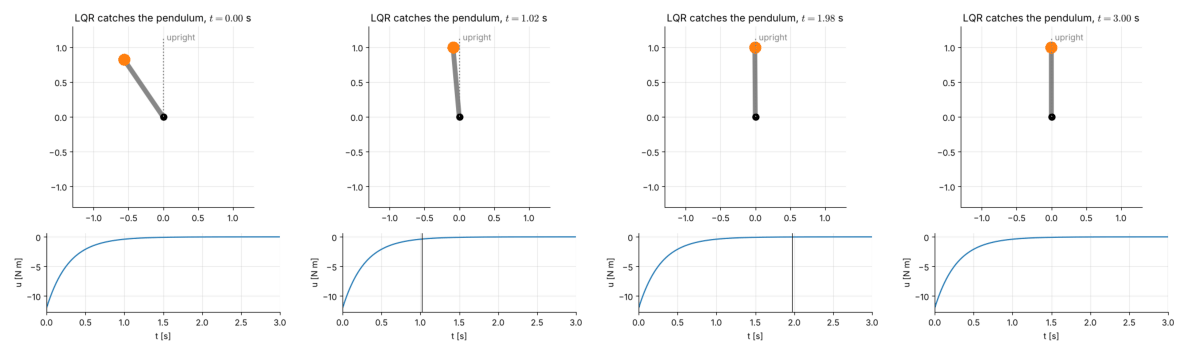

final deviation from upright: 0.000354 rad;  peak torque 12.07 N m


In [6]:
def simulate_pendulum(K, x0, T=4.0, dt=0.005, u_ref=0.0, x_ref=(np.pi, 0.0), umax=np.inf, disturbance=0.0):
    f = lambda x, u: pend_f(x, u + disturbance)
    n = int(T / dt); X = np.zeros((n + 1, 2)); U = np.zeros(n); X[0] = x0
    for k in range(n):
        U[k] = np.clip(u_ref - (K @ (X[k] - np.array(x_ref)))[0], -umax, umax)
        X[k + 1] = oc.rk4_step(f, X[k], np.array([U[k]]), dt)
    return np.arange(n + 1) * dt, X, U

x0_p = np.array([np.pi + 0.6, 0.0])
t, X, U = simulate_pendulum(K_c, x0_p, T=3.0)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(5.2, 6.4), gridspec_kw=dict(height_ratios=[3, 1.3]))
idx = np.linspace(0, len(t) - 1, 45).astype(int)

def update(i):
    ax.cla(); ax2.cla()
    th = X[i, 0]
    tip = np.array([np.sin(th) * ell, -np.cos(th) * ell])
    ax.plot([0, tip[0]], [0, tip[1]], "-", color="#555", lw=6, solid_capstyle="round", alpha=0.7)
    ax.plot(0, 0, "ko", ms=8); ax.plot(*tip, "o", color="#ff7f0e", ms=14)
    ax.plot([0, 0], [0, ell * 1.15], ":", color="grey"); ax.text(0.05, 1.1, "upright", color="grey")
    ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal"); ax.set_title(rf"LQR catches the pendulum, $t={t[i]:.2f}$ s")
    ax2.plot(t[:-1], U, color="C0"); ax2.axvline(t[i], color="k", lw=0.8)
    ax2.set_xlabel("t [s]"); ax2.set_ylabel("u [N m]"); ax2.set_xlim(0, 3.0)

animate(fig, update, idx, interval=70, gif="assets/7.1-lqr-pendulum.gif")
print("final deviation from upright:", abs(X[-1, 0] - np.pi).round(6), "rad;  peak torque", np.abs(U).max().round(2), "N m")

## 4. Choosing $Q$ and $R$

The weights are the designer's interface. Three practical facts make them manageable.

**Only ratios matter.** Multiplying $Q$ and $R$ by the same constant multiplies $J$ and $P$ by that constant but leaves
$K$ unchanged. One weight can therefore be fixed, and the others read as "relative importance".

**Bryson's rule.** Normalise each term by the largest value one is willing to tolerate:

$$
Q_{ii} = \frac{1}{(\Delta x_i^{\max})^2},\qquad R_{jj} = \frac{1}{(u_j^{\max})^2}.
$$

Then $\mathbf x^{\mathsf T}Q\mathbf x + \mathbf u^{\mathsf T}R\mathbf u$ equals $n+m$ when every variable sits at its limit, so the
terms are comparable. Bryson's rule is a starting point; one then scales $Q$ up or down to move along the trade-off curve below.

**The two limits.** If control is *expensive* ($R\to\infty$) the regulator uses as little effort as possible: stable poles
stay where they are and unstable poles are *reflected* into the left half-plane (the cheapest way to stabilise). If control is
*cheap* ($R\to0$) the poles move to infinity along asymptotes that depend only on the numerator of the transfer function
from input to the cost output, and the control signal grows without bound. Between the limits the poles trace a curve, the
*symmetric root locus*, shown for the pendulum in the left panel below. The right panel plots, for the pendulum started at
$\varphi_0=0.3$, the achieved state cost against the achieved control cost for the LQR family (blue) and for a cloud of
arbitrary stabilising gains $K=[k_1,k_2]$ (grey): **no linear feedback is below the LQR curve** — that is exactly what optimality means.

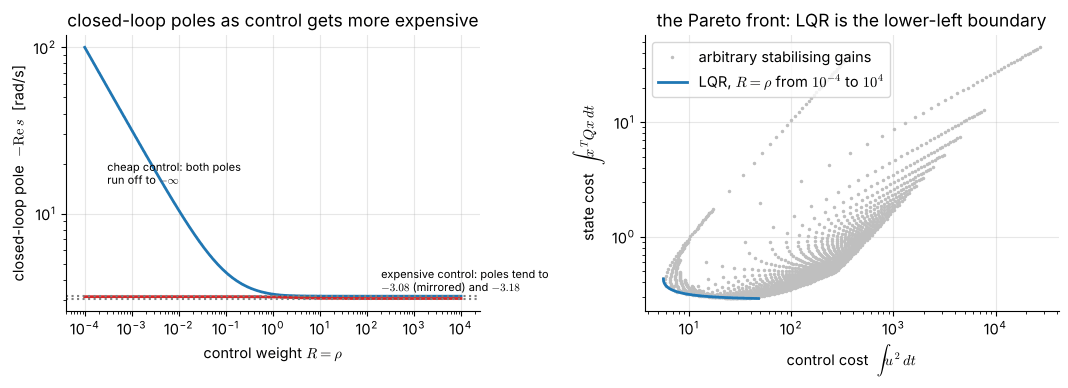

expensive-control limit -> poles [-3.182 -3.083]  (open loop: +3.0825 mirrored to -3.0825, and -3.1825)
every arbitrary gain costs more than the LQR optimum for every trade-off weight rho: True


In [7]:
Qw = np.diag([10.0, 1.0])
rhos = np.logspace(-4, 4, 80)
poles = np.array([np.linalg.eigvals(A_c - B_c @ oc.lqr(A_c, B_c, Qw, np.array([[r]]))[0]) for r in rhos])

x0c = np.array([0.3, 0.0])
def costs_of_gain(K):
    Acl = A_c - B_c @ K
    Xq = sla.solve_continuous_lyapunov(Acl.T, -Qw)                 # int x'Qx dt   = x0' Xq x0
    Xu = sla.solve_continuous_lyapunov(Acl.T, -(K.T @ K))           # int u'u  dt   = x0' Xu x0
    return x0c @ Xq @ x0c, x0c @ Xu @ x0c

front = np.array([costs_of_gain(oc.lqr(A_c, B_c, Qw, np.array([[r]]))[0]) for r in rhos])
cloud = np.array([costs_of_gain(np.array([[k1, k2]])) for k1 in np.linspace(10.5, 600, 40) for k2 in np.linspace(0.5, 60, 40)])

fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.0))
for j, col in enumerate(("C0", "C3")):
    axs[0].semilogx(rhos, -np.sort(poles.real, axis=1)[:, j], color=col, lw=2)
axs[0].axhline(3.0825, color="grey", ls=":"); axs[0].axhline(3.1825, color="grey", ls=":")
axs[0].set_yscale("log"); axs[0].set_xlabel(r"control weight $R=\rho$"); axs[0].set_ylabel(r"closed-loop pole  $-\mathrm{Re}\,s$  [rad/s]")
axs[0].annotate("expensive control: poles tend to\n$-3.08$ (mirrored) and $-3.18$", (2e2, 3.4), fontsize=8)
axs[0].annotate("cheap control: both poles\nrun off to $-\\infty$", (3e-4, 15), fontsize=8)
axs[0].set_title("closed-loop poles as control gets more expensive")
axs[1].loglog(cloud[:, 1], cloud[:, 0], ".", color="0.75", ms=3, label="arbitrary stabilising gains")
axs[1].loglog(front[:, 1], front[:, 0], "-", color="C0", lw=2, label="LQR, $R=\\rho$ from $10^{-4}$ to $10^{4}$")
axs[1].set_xlabel(r"control cost  $\int u^2\,dt$"); axs[1].set_ylabel(r"state cost  $\int x^{T}Qx\,dt$"); axs[1].legend()
axs[1].set_title("the Pareto front: LQR is the lower-left boundary")
plt.tight_layout(); plt.show()
print("expensive-control limit -> poles", np.sort(poles[-1].real).round(3), " (open loop: +3.0825 mirrored to -3.0825, and -3.1825)")
print("every arbitrary gain costs more than the LQR optimum for every trade-off weight rho:",
      all((cloud[:, 0] + r * cloud[:, 1]).min() >= (front[:, 0] + r * front[:, 1]).min() - 1e-9 for r in rhos))

**Explorer.** Change the three weights below. The left plot is the response of the *nonlinear* pendulum, the right plot the
torque. Notice that a larger state weight shortens the transient but demands a larger initial torque (the first
instant of the response is dominated by $K\mathbf x_0$), while a larger $R$ gives a slow, gentle return.

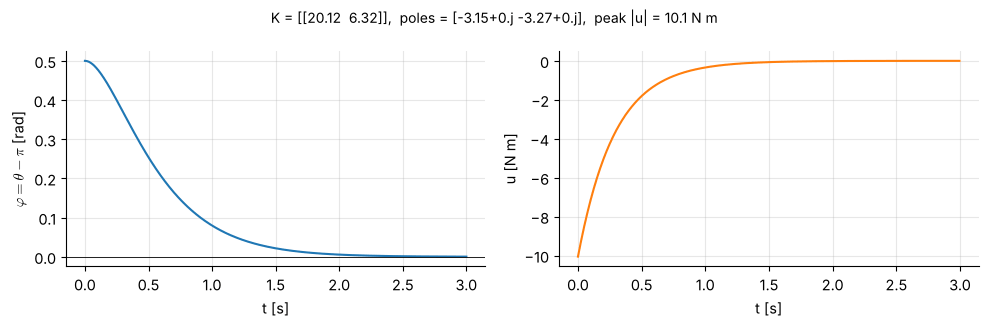

In [8]:
def explore(log10_q_theta=1.0, log10_q_omega=0.0, log10_r=0.0, phi0=0.5):
    Q_ = np.diag([10 ** log10_q_theta, 10 ** log10_q_omega]); R_ = np.array([[10 ** log10_r]])
    K_, _ = oc.lqr(A_c, B_c, Q_, R_)
    t, X, U = simulate_pendulum(K_, np.array([np.pi + phi0, 0.0]), T=3.0)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
    axs[0].plot(t, X[:, 0] - np.pi, color="C0"); axs[0].axhline(0, color="k", lw=0.6)
    axs[0].set_xlabel("t [s]"); axs[0].set_ylabel(r"$\varphi=\theta-\pi$ [rad]")
    axs[1].plot(t[:-1], U, color="C1"); axs[1].set_xlabel("t [s]"); axs[1].set_ylabel("u [N m]")
    poles_ = np.linalg.eigvals(A_c - B_c @ K_)
    fig.suptitle(f"K = {K_.round(2)},  poles = {np.round(poles_, 2)},  peak |u| = {np.abs(U).max():.1f} N m", fontsize=10)
    plt.tight_layout(); plt.show()

interact(explore, log10_q_theta=widgets.FloatSlider(value=1.0, min=-1, max=4, step=0.25, description="log10 q_θ"),
         log10_q_omega=widgets.FloatSlider(value=0.0, min=-2, max=3, step=0.25, description="log10 q_ω"),
         log10_r=widgets.FloatSlider(value=0.0, min=-3, max=3, step=0.25, description="log10 r"),
         phi0=widgets.FloatSlider(value=0.5, min=0.1, max=1.2, step=0.1, description="φ₀ [rad]"))

## 5. Why LQR is robust

A property that distinguishes LQR from an arbitrary pole placement is its **guaranteed stability margin**. Let
$L(s)=K(sI-A)^{-1}B$ be the loop gain obtained by cutting the loop at the plant input. Kalman showed that the Riccati
solution satisfies, for all frequencies $\omega$, the **return-difference inequality**

$$
\big(I + L(j\omega)\big)^{*}R\,\big(I + L(j\omega)\big) \succeq R
\quad\Longrightarrow\quad \lvert 1 + L(j\omega)\rvert \ge 1 \ \text{ for a single input.}
$$

Geometrically the Nyquist curve never enters the unit disc centred at $-1$. Two famous corollaries for a single-input
loop: the **gain margin** is at least $(\tfrac12, \infty)$ — the loop gain may be reduced by half or increased arbitrarily
without losing stability — and the **phase margin** is at least $60^\circ$. The inequality follows from rearranging the
ARE (subtract $sP - sP$ in a suitable way), and a derivation can be found in the references; here we check it numerically.
(The guarantee applies to *full-state feedback*. Once the state is estimated by an observer the guarantee can be lost, which
is why measured-state designs are tested separately.)

min |1 + L(jw)| over all w : 1.0  (>= 1 as guaranteed)
closed loop stable for kappa >= 0.488  (theory: kappa > g/k1 = 0.488 <= 1/2)


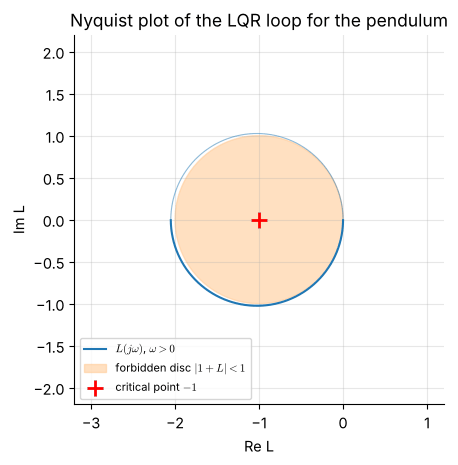

|L| = 1 at w = 5.52 rad/s; phase margin = 60.8 deg (>= 60 deg)


In [9]:
w = np.logspace(-2, 3, 4000)
L = np.array([(K_c @ np.linalg.solve(1j * wi * np.eye(2) - A_c, B_c))[0, 0] for wi in w])
print("min |1 + L(jw)| over all w :", np.abs(1 + L).min().round(4), " (>= 1 as guaranteed)")

# smallest and largest loop-gain scaling kappa for which A - kappa B K is stable
kappas = np.linspace(0.05, 5, 2000)
stable = np.array([np.all(np.linalg.eigvals(A_c - k * B_c @ K_c).real < 0) for k in kappas])
print(f"closed loop stable for kappa >= {kappas[stable][0]:.3f}  (theory: kappa > g/k1 = {g / K_c[0, 0]:.3f} <= 1/2)")

fig, ax = plt.subplots(figsize=(5.2, 4.8))
ax.plot(L.real, L.imag, color="C0", label=r"$L(j\omega)$, $\omega>0$"); ax.plot(L.real, -L.imag, color="C0", lw=0.8, alpha=0.5)
th = np.linspace(0, 2 * np.pi, 200)
ax.fill(-1 + np.cos(th), np.sin(th), color="#ffcc99", alpha=0.6, label="forbidden disc $|1+L|<1$")
ax.plot([-1], [0], "r+", ms=12, mew=2, label="critical point $-1$")
ax.set_xlim(-3.2, 1.2); ax.set_ylim(-2.2, 2.2); ax.set_aspect("equal"); ax.set_xlabel("Re L"); ax.set_ylabel("Im L")
ax.legend(fontsize=8, loc="lower left"); ax.set_title("Nyquist plot of the LQR loop for the pendulum")
plt.show()
# phase margin: frequency where |L| = 1
iw = np.argmin(np.abs(np.abs(L) - 1)); pm = 180 + np.degrees(np.angle(L[iw]))
print(f"|L| = 1 at w = {w[iw]:.2f} rad/s; phase margin = {pm:.1f} deg (>= 60 deg)")

## 6. Set-points, tracking and integral action

The regulator drives $\mathbf x$ to $\mathbf 0$. A robot must hold a *posture* or follow a *reference*, and the
posture is rarely an equilibrium with zero input: a horizontal arm needs a holding torque against gravity.

**Equilibrium shifting.** Suppose the target is a state $\mathbf x^\star$ with the input $\mathbf u^\star$ that keeps it
there, $A\mathbf x^\star + B\mathbf u^\star = \mathbf 0$ (for a nonlinear plant $\mathbf f(\mathbf x^\star,\mathbf u^\star)=\mathbf 0$ and
$A,B$ are Jacobians at that point). Writing $\tilde{\mathbf x}=\mathbf x-\mathbf x^\star$ and $\tilde{\mathbf u}=\mathbf u-\mathbf u^\star$
gives $\dot{\tilde{\mathbf x}}=A\tilde{\mathbf x}+B\tilde{\mathbf u}$, so

$$
\mathbf u = \mathbf u^\star - K(\mathbf x - \mathbf x^\star).
$$

For a pendulum held at an angle $\varphi_r$ from upright, $\mathbf x^\star=(\varphi_r,0)$ and
$u^\star = -m g\ell\sin\varphi_r\approx -m g\ell\,\varphi_r$ (the torque that balances gravity at that angle). Omitting the feed-forward
$u^\star$ leaves a steady-state error: in the linear model with $m\ell^2=1$ and negligible damping, $\ddot\varphi = (g/\ell)\varphi - k_1(\varphi-\varphi_r)$
settles at $\varphi - \varphi_r = \dfrac{(g/\ell)\,\varphi_r}{k_1-g/\ell}$, which the figure below confirms.

**Integral action.** The feed-forward $\mathbf u^\star$ is computed from the *model*. If the model is wrong — an unknown payload,
a constant disturbance torque $d$ — the hold is imperfect. With a constant disturbance, $\ddot\varphi = (g/\ell)\varphi + u + d$ and the
static feedback settles where $-k_1\varphi + (g/\ell)\varphi + d = 0$, i.e. at $\varphi_{ss}=d/(k_1-g/\ell)\neq0$. The classical remedy
is an integrator on the error. Augment the state with $z=\int(\varphi-\varphi_r)\,dt$ (so $\dot z = \varphi-\varphi_r$) and design LQR for

$$
\frac{d}{dt}\begin{bmatrix}\tilde{\mathbf x}\\ z\end{bmatrix}
= \begin{bmatrix}A & \mathbf 0\\ C & 0\end{bmatrix}\begin{bmatrix}\tilde{\mathbf x}\\ z\end{bmatrix}
+ \begin{bmatrix}B\\0\end{bmatrix}\tilde u,\qquad C=[1\ \ 0],
$$

which is controllable when $(A,B)$ is and the plant has no transmission zero at the origin. A stable closed loop must have
$\dot z\to0$, hence $\varphi\to\varphi_r$ whatever the constant disturbance is — the *internal model principle*, familiar from the I-term of a PID controller. The weight on $z$ trades speed of disturbance rejection
against overshoot.

u* linear = -2.4525,  u* exact (nonlinear) = -2.4270 N m
augmented gain [k1 k2 ki] = [[22.741  6.719  4.472]]   poles: [-3.418+0.j -2.958+0.j -0.442+0.j]


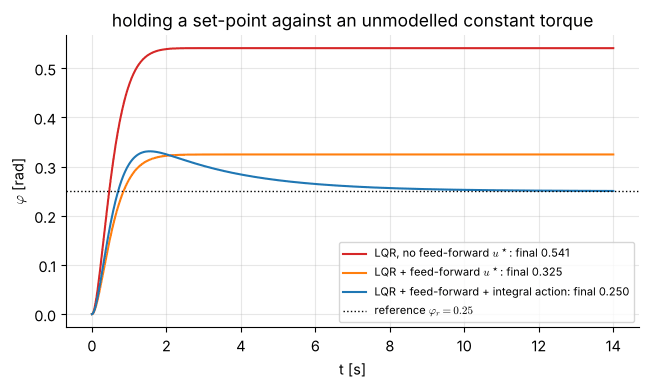

steady-state error (angle minus reference), simulated nonlinear plant vs linear-model prediction:
  no feed-forward           : +0.2908   predicted (g*phi_r + d)/(k1-g) = +0.3156
  with feed-forward         : +0.0747   predicted d/(k1-g)            = +0.0776
  with integral action      : +0.0005   (integrator removes the offset)


In [10]:
phi_r, d_dist = 0.25, 0.8                           # hold 0.25 rad away from upright against an unmodelled 0.8 N m disturbance
x_star = np.array([np.pi + phi_r, 0.0])
u_star_lin = -(g / ell) * mass * ell ** 2 * phi_r   # from A x* + B u* = 0 (linear model)
u_star_exact = mass * g * ell * np.sin(np.pi + phi_r)   # torque balance u - m g l sin(theta) = 0 at theta = pi + phi_r
print(f"u* linear = {u_star_lin:.4f},  u* exact (nonlinear) = {u_star_exact:.4f} N m")

# integral-action LQR on the augmented linear model
Aa = np.block([[A_c, np.zeros((2, 1))], [np.array([[1.0, 0.0]]), np.zeros((1, 1))]])
Ba = np.vstack([B_c, [[0.0]]])
Ka, _ = oc.lqr(Aa, Ba, np.diag([10.0, 1.0, 20.0]), np.array([[1.0]]))
print("augmented gain [k1 k2 ki] =", Ka.round(3), "  poles:", np.sort_complex(np.linalg.eigvals(Aa - Ba @ Ka)).round(3))

def run(controller, T=14.0, dt=0.005, x0=np.array([np.pi, 0.0]), dist=d_dist):
    n = int(T / dt); X = np.zeros((n + 1, 2)); U = np.zeros(n); z = 0.0; X[0] = x0
    for k in range(n):
        U[k] = controller(X[k], z)
        X[k + 1] = oc.rk4_step(lambda x, u: pend_f(x, u + dist), X[k], np.array([U[k]]), dt)
        z += dt * (X[k, 0] - x_star[0])
    return np.arange(n + 1) * dt, X, U

ctrls = {
    r"LQR, no feed-forward $u^\star$": lambda x, z: -(K_c @ (x - x_star))[0],
    r"LQR + feed-forward $u^\star$": lambda x, z: u_star_exact - (K_c @ (x - x_star))[0],
    "LQR + feed-forward + integral action": lambda x, z: u_star_exact - (Ka[:, :2] @ (x - x_star))[0] - Ka[0, 2] * z,
}
fig, ax = plt.subplots(figsize=(7.4, 3.8))
for (name, c), col in zip(ctrls.items(), ("C3", "C1", "C0")):
    t, X, U = run(c); ax.plot(t, X[:, 0] - np.pi, color=col, label=f"{name}: final {X[-1, 0] - np.pi:.3f}")
ax.axhline(phi_r, color="k", ls=":", lw=1, label=r"reference $\varphi_r=0.25$")
ax.set_xlabel("t [s]"); ax.set_ylabel(r"$\varphi$ [rad]"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("holding a set-point against an unmodelled constant torque")
plt.show()
res_final = {}
for name, c in ctrls.items():
    t, X, U = run(c); res_final[name] = X[-1, 0] - np.pi - phi_r
k1, gl = K_c[0, 0], g / ell
print("steady-state error (angle minus reference), simulated nonlinear plant vs linear-model prediction:")
print(f"  no feed-forward           : {res_final[list(ctrls)[0]]:+.4f}   predicted (g*phi_r + d)/(k1-g) = {(gl * phi_r + d_dist) / (k1 - gl):+.4f}")
print(f"  with feed-forward         : {res_final[list(ctrls)[1]]:+.4f}   predicted d/(k1-g)            = {d_dist / (k1 - gl):+.4f}")
print(f"  with integral action      : {res_final[list(ctrls)[2]]:+.4f}   (integrator removes the offset)")

## 7. LQR on real robots in MuJoCo

A robot arm is a fully actuated mechanical system, $M(\mathbf q)\ddot{\mathbf q} + \mathbf h(\mathbf q,\dot{\mathbf q}) = \boldsymbol\tau$,
where $\mathbf h$ collects Coriolis, centrifugal and gravity terms. Around a posture $\mathbf q_0$ held at rest by the
torque $\boldsymbol\tau_0=\mathbf g(\mathbf q_0)$, the linearisation in $\mathbf x=(\mathbf q,\dot{\mathbf q})$ is

$$
\frac{d}{dt}\begin{bmatrix}\delta\mathbf q\\ \delta\dot{\mathbf q}\end{bmatrix}
= \begin{bmatrix}0 & I\\ -M^{-1}G & -M^{-1}\partial_{\dot q}\mathbf h\end{bmatrix}\begin{bmatrix}\delta\mathbf q\\ \delta\dot{\mathbf q}\end{bmatrix}
+ \begin{bmatrix}0\\ M^{-1}\end{bmatrix}\delta\boldsymbol\tau,\qquad G=\frac{\partial\mathbf g}{\partial\mathbf q}\Big|_{\mathbf q_0},
$$

(velocity terms vanish at rest, and the term $\partial_q(M^{-1})(\boldsymbol\tau_0-\mathbf g)$ vanishes because $\boldsymbol\tau_0=\mathbf g$). The
matrix $G$ is the Hessian of the potential energy: when the arm is raised above its shoulder the potential has a *maximum* in some
direction, $G$ has a negative eigenvalue, and the arm is **open-loop unstable** like the inverted pendulum. Holding such a
posture is therefore a genuine stabilisation problem, and a good first test of LQR on hardware-like dynamics.

We use the **Dynamixel 2R** arm of MuJoCo Menagerie (a two-link arm moving in the vertical $x$–$z$ plane), converted to
ideal joint-torque inputs by `rgkit.mj_control` (the manufacturer's position-servo actuators are replaced by torque sources, torque limit
$\pm6\ \mathrm{N\,m}$ per joint). The design model has **no joint friction and no payload**; the "true" plant on which we test
the controller has Coulomb friction ($0.1\ \mathrm{N\,m}$ per joint, as in the manufacturer's model) and a $0.15\ \mathrm{kg}$ mass at
the tool that the designer does not know about. The sampling time is $\Delta t = 10\ \mathrm{ms}$; the plant is the exact one-step map of the
simulator, $\mathbf x_{k+1}=f(\mathbf x_k,\boldsymbol\tau_k)$, and `mjd_transitionFD` supplies its Jacobians $A_d = \partial f/\partial\mathbf x$ and $B_d = \partial f/\partial\boldsymbol\tau$ by centred finite differences *inside the C engine*.

**Cross-check with the hand derivation.** MuJoCo's default integrator is semi-implicit Euler, $\dot{\mathbf q}_{k+1}=\dot{\mathbf q}_k + \Delta t\,M^{-1}(\boldsymbol\tau-\mathbf h)$,
$\mathbf q_{k+1} = \mathbf q_k + \Delta t\,\dot{\mathbf q}_{k+1}$. Differentiating at the equilibrium, with $G=\partial\mathbf g/\partial\mathbf q$ obtained from
the simulator's own gravity torque,

$$
A_d = \begin{bmatrix} I - \Delta t^2M^{-1}G & \Delta t\,I\\ -\Delta t\,M^{-1}G & I\end{bmatrix},\qquad
B_d = \begin{bmatrix}\Delta t^2M^{-1}\\ \Delta t\,M^{-1}\end{bmatrix}.
$$

In [11]:
dt = 0.01
design = mc.TorquePlant(mc.make_arm("2r", frictionloss=0.0, dt=dt), site="end")          # nominal model
true_plant = mc.TorquePlant(mc.make_arm("2r", frictionloss=0.1, payload=0.15, dt=dt), site="end")   # what the controller really faces
q0 = np.array([1.5, 0.4]); x0 = np.r_[q0, 0.0, 0.0]
u0 = design.gravity(q0)                                       # holding torque g(q0) from MuJoCo's own bias force
A_mj, B_mj = design.linearize(x0, u0)                         # mjd_transitionFD

M0 = design.mass_matrix(q0); Minv = np.linalg.inv(M0)
G = oc.numerical_jacobian(design.gravity, q0)                 # dg/dq by finite differences of MuJoCo's gravity torque
I2 = np.eye(2)
A_hand = np.block([[I2 - dt ** 2 * Minv @ G, dt * I2], [-dt * Minv @ G, I2]])
B_hand = np.vstack([dt ** 2 * Minv, dt * Minv])
print("holding torque g(q0) =", u0.round(4), "N m   tool at", design.tool_position(q0).round(3), "m")
print("max |A_mujoco - A_hand| =", np.abs(A_mj - A_hand).max(), "   max |B_mujoco - B_hand| =", np.abs(B_mj - B_hand).max())
assert np.allclose(A_mj, A_hand, atol=1e-8) and np.allclose(B_mj, B_hand, atol=1e-8)
print("eigenvalues of -M^-1 G (the 'gravity stiffness' in rad^2/s^2):", np.linalg.eigvals(-Minv @ G).round(3))
s_open = np.log(np.linalg.eigvals(A_mj).astype(complex)) / dt
print("open-loop continuous-time poles of the arm [rad/s]:", np.sort_complex(s_open).round(3), " -> unstable")

holding torque g(q0) = [4.1268 1.7999] N m   tool at [0.35  0.    0.591] m
max |A_mujoco - A_hand| = 4.0941738888022883e-10    max |B_mujoco - B_hand| = 8.372391668842738e-11
eigenvalues of -M^-1 G (the 'gravity stiffness' in rad^2/s^2): [-3.41 +0.j 20.399+0.j]
open-loop continuous-time poles of the arm [rad/s]: [-4.516+0.j    -0.   -1.847j -0.   +1.847j  4.516+0.j   ]  -> unstable


The hand-derived and MuJoCo matrices agree to $10^{-8}$, and the open-loop poles confirm that the posture is unstable
(one real pole near $+4.5\ \mathrm{rad/s}$: the arm falls away with a time constant of about $0.22\ \mathrm{s}$).

**Design.** Following Bryson's rule we accept $0.1\ \mathrm{rad}$ of joint error, $1\ \mathrm{rad/s}$ of joint speed and
$3\ \mathrm{N\,m}$ of additional torque, giving $Q=\mathrm{diag}(100,100,1,1)$ and $R\approx0.1\,I$. The gain matrix is $2\times4$. Note that it is **not diagonal**: joint 1's
torque depends on the error of joint 2 and vice versa. A bank of independent joint PD controllers cannot represent this coupling; LQR obtains it for free from $M^{-1}$.

We compare against the best simple alternative: gravity compensation plus an independent PD law per joint, with the
natural frequency $\omega_n = 6\ \mathrm{rad/s}$ and critical damping chosen from the diagonal of $M$,
$K_{p,i}=M_{ii}\omega_n^2,\ K_{d,i}=2M_{ii}\omega_n$ (the textbook recipe of independent-joint control). Both controllers start from an offset of $(0.15,-0.10)\ \mathrm{rad}$ with zero velocity.

In [12]:
Q = np.diag([100.0, 100.0, 1.0, 1.0]); R = 0.1 * np.eye(2)
K, P = oc.dlqr(A_mj, B_mj, Q, R)
print("LQR gain K (rows: torque of joint 1, 2; columns: q1, q2, qd1, qd2):\n", K.round(2))
print("closed-loop continuous-time poles [rad/s]:", np.sort_complex(np.log(np.linalg.eigvals(A_mj - B_mj @ K).astype(complex)) / dt).round(1))

wn = 6.0
Kp, Kd = np.diag(M0) * wn ** 2, 2 * np.diag(M0) * wn
ctrl_lqr = lambda x: u0 - K @ (x - x0)
ctrl_pd = lambda x: design.gravity(x[:2]) - Kp * (x[:2] - q0) - Kd * x[2:]
ctrl_open = lambda x: u0 + 0 * x[:2]

def run_loop(plant, ctrl, xinit, T=300):
    X, U = [np.array(xinit, float)], []
    x = plant.reset(xinit)
    for _ in range(T):
        u = plant.clip(ctrl(x)); x = plant.step(u); X.append(x.copy()); U.append(u)
    return np.array(X), np.array(U)

def lq_cost(X, U):
    return sum((X[k] - x0) @ Q @ (X[k] - x0) + (U[k] - u0) @ R @ (U[k] - u0) for k in range(len(U)))

xi = x0 + np.array([0.15, -0.10, 0.0, 0.0])
out = {}
for name, ctrl in [("LQR", ctrl_lqr), ("PD + gravity comp.", ctrl_pd), ("gravity feed-forward only", ctrl_open)]:
    for plant_name, plant in [("nominal", design), ("true", true_plant)]:
        out[(name, plant_name)] = run_loop(plant, ctrl, xi)
print("\n{:28s} {:>14s} {:>14s} {:>22s}".format("controller", "cost, nominal", "cost, true", "final |q - q0| (true)"))
for name in ("LQR", "PD + gravity comp.", "gravity feed-forward only"):
    Xn, Un = out[(name, "nominal")]; Xt, Ut = out[(name, "true")]
    costs = ("{:14.1f} {:14.1f}".format(lq_cost(Xn, Un), lq_cost(Xt, Ut)) if "only" not in name else "{:>14s} {:>14s}".format("diverges", "diverges"))
    print("{:28s} {} {:22.4f}".format(name, costs, np.abs(Xt[-1, :2] - q0).max()))
print("\nvalue-function prediction x0' P x0 for the LQR cost (linear model):", round((xi - x0) @ P @ (xi - x0), 2))

LQR gain K (rows: torque of joint 1, 2; columns: q1, q2, qd1, qd2):
 [[24.24  8.78  3.46  1.34]
 [ 8.87 11.83  1.35  1.42]]
closed-loop continuous-time poles [rad/s]: [-287.2+0.j  -12.8-3.j  -12.8+3.j  -10. +0.j]



controller                    cost, nominal     cost, true  final |q - q0| (true)
LQR                                    37.8           68.2                 0.0248
PD + gravity comp.                    250.7          688.9                 0.1322
gravity feed-forward only          diverges       diverges                 0.6454

value-function prediction x0' P x0 for the LQR cost (linear model): 37.73


Three results stand out. The value-function prediction $\tilde{\mathbf x}_0^{\mathsf T}P\tilde{\mathbf x}_0$ agrees with the cost *measured in the
nonlinear simulator* to within a fraction of a percent: the Riccati matrix really is the cost-to-go. Second, the LQR cost is several times smaller than the cost of the
hand-tuned independent-joint PD law (the PD law is stable and reasonable, but it is not designed with respect to this cost, and it ignores the coupling).
Third, without feedback the arm falls. On the "true" plant the LQR leaves a small residual offset of a few hundredths of a radian — the effect of the
unmodelled payload and of stiction, which no static feedback on $\mathbf x$ can remove; Section 6's integral action does, as the UR5e example below demonstrates.
The animation shows the open-loop fall next to the LQR hold.

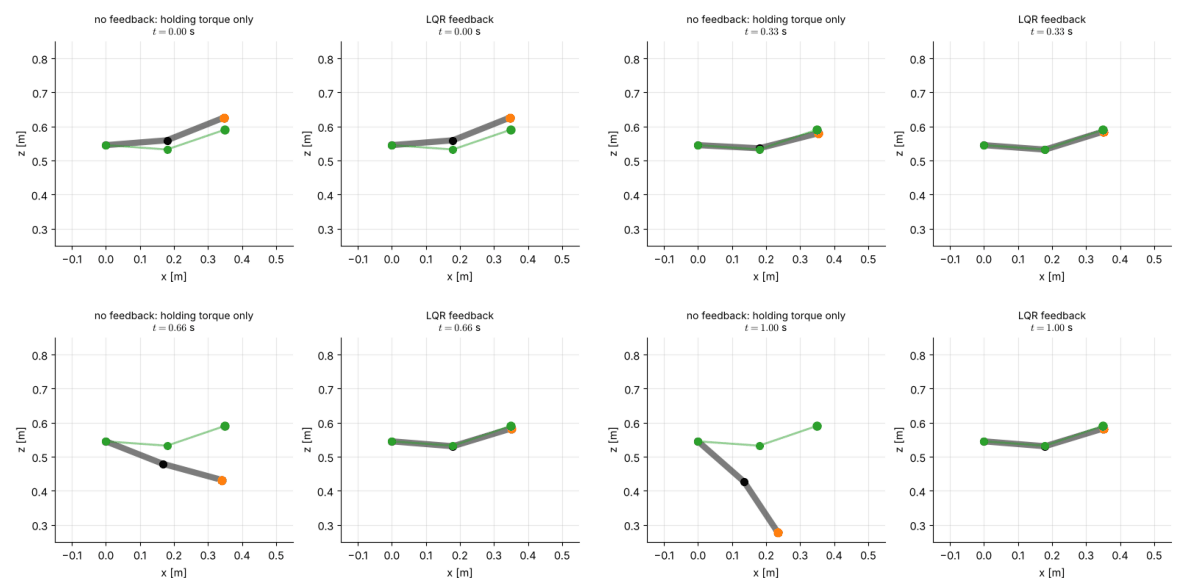

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(9.2, 3.8))
Xo, Xl = out[("gravity feed-forward only", "true")][0], out[("LQR", "true")][0]
frames = np.linspace(0, 100, 40).astype(int)

def update(i):
    for ax, Xs, title in zip(axs, (Xo, Xl), ("no feedback: holding torque only", "LQR feedback")):
        ax.cla()
        mc.draw_arm_xz(ax, design.joint_positions(Xs[i, :2]))
        mc.draw_arm_xz(ax, design.joint_positions(q0), color="C2", lw=2, alpha=0.5, joint_color="C2", tool_color="C2")
        ax.set_xlim(-0.15, 0.55); ax.set_ylim(0.25, 0.85); ax.set_aspect("equal")
        ax.set_title(f"{title}\n$t={0.01 * i:.2f}$ s", fontsize=10); ax.set_xlabel("x [m]"); ax.set_ylabel("z [m]")

animate(fig, update, frames, interval=70, gif="assets/7.1-lqr-2r-posture.gif")

The figure below shows the joint errors and torques for the LQR and PD controllers on the true plant, and one MuJoCo render of the arm at the commanded posture (green ghost in the animation above is the target).

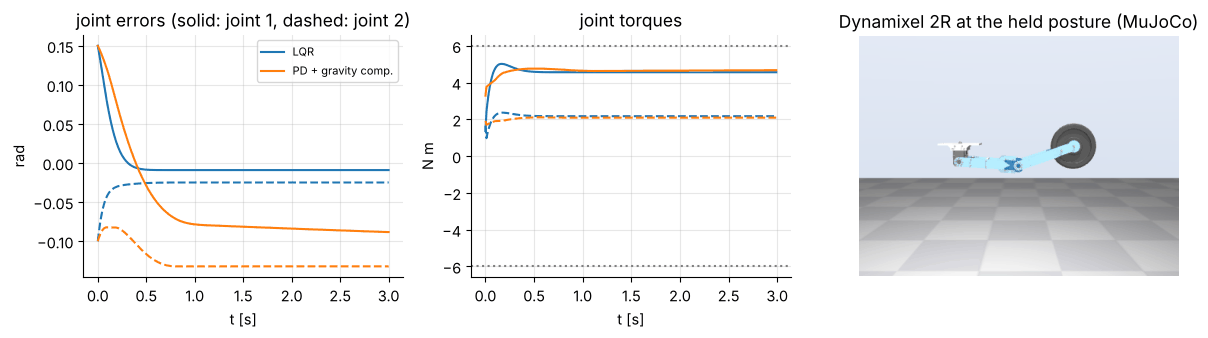

Dynamixel 2R arm — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/dynamixel_2r) (Marc Duclusaud & Grégoire Passault; licence: MIT)


In [14]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
tt = np.arange(301) * dt
for (name, col) in (("LQR", "C0"), ("PD + gravity comp.", "C1")):
    X, U = out[(name, "true")]
    axs[0].plot(tt, X[:, 0] - q0[0], color=col, label=f"{name}"); axs[0].plot(tt, X[:, 1] - q0[1], color=col, ls="--")
    axs[1].plot(tt[:-1], U[:, 0], color=col); axs[1].plot(tt[:-1], U[:, 1], color=col, ls="--")
axs[0].set_title("joint errors (solid: joint 1, dashed: joint 2)"); axs[0].set_ylabel("rad"); axs[0].legend(fontsize=8)
axs[1].set_title("joint torques"); axs[1].set_ylabel("N m"); axs[1].axhline(6, color="grey", ls=":"); axs[1].axhline(-6, color="grey", ls=":")
for ax in axs[:2]: ax.set_xlabel("t [s]")
design.reset(x0)
img = mju.render(design.model, design.data, camera=dict(azimuth=90, elevation=-5, distance=0.9, lookat=(0.18, 0, 0.56)),
                 width=420, height=315)
axs[2].imshow(img); axs[2].set_axis_off(); axs[2].set_title("Dynamixel 2R at the held posture (MuJoCo)")
plt.tight_layout(); plt.show()
print(robots.describe("2r"))

### A six-joint arm: the UR5e holding a payload

Nothing in the method depends on the number of joints. For the **Universal Robots UR5e** we linearise at the manufacturer's "home" posture
(upper arm and forearm horizontal), where the arm is again open-loop unstable ($A_d$ has an eigenvalue outside the unit circle), solve a $12$-state, $6$-input LQR in one call, and
test it on a plant carrying a **1 kg** payload at the flange that the design ignores. The model's own limits are kept: $150\ \mathrm{N\,m}$ for the first three joints and $28\ \mathrm{N\,m}$ for the wrist.

Because the payload shifts the equilibrium, the static LQR sags (the tool drops by several centimetres); adding the integral action of Section 6 on the six joint errors — a $18$-state augmented LQR — removes the offset completely.

UR5e holding torque g(q): [  0.   -15.86 -15.86  -1.38  -0.    -0.  ] N m
A_d is (12, 12) ; spectral radius of A_d = 1.0531 (> 1: unstable)


static LQR            : final joint error 3.83e-02 rad,  tool displacement [  0.17   4.87 -36.11] mm
LQR + integral action : final joint error 8.67e-09 rad,  tool displacement [ 0.  0. -0.] mm


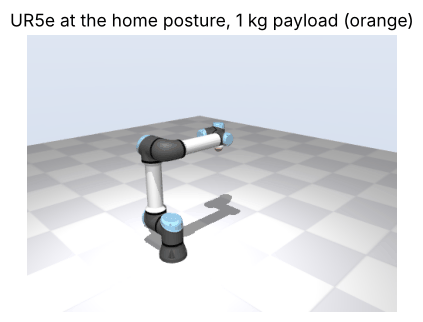

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)


In [15]:
ur_design = mc.TorquePlant(mc.make_arm("ur5e", frictionloss=0.0, dt=dt), site="attachment_site")
ur_true = mc.TorquePlant(mc.make_arm("ur5e", frictionloss=0.0, payload=1.0, dt=dt), site="attachment_site")
qh = np.array([-1.5708, -1.5708, 1.5708, -1.5708, -1.5708, 0.0]); xh = np.r_[qh, np.zeros(6)]
uh = ur_design.gravity(qh)
Au, Bu = ur_design.linearize(xh, uh)
print("UR5e holding torque g(q):", uh.round(2), "N m")
print("A_d is", Au.shape, "; spectral radius of A_d =", np.abs(np.linalg.eigvals(Au)).max().round(4), "(> 1: unstable)")

Qu = np.diag([200.0] * 6 + [2.0] * 6); Ru = 0.01 * np.eye(6)
Ku, _ = oc.dlqr(Au, Bu, Qu, Ru)
Aaug = np.block([[Au, np.zeros((12, 6))], [dt * np.hstack([np.eye(6), np.zeros((6, 6))]), np.eye(6)]])
Baug = np.vstack([Bu, np.zeros((6, 6))])
Kaug, _ = oc.dlqr(Aaug, Baug, np.diag([200.0] * 6 + [2.0] * 6 + [2000.0] * 6), Ru)

def run_ur(use_integral, T=500, offset=0.05):
    x = ur_true.reset(xh + np.r_[offset * np.ones(6), np.zeros(6)]); z = np.zeros(6); X = [x.copy()]
    for _ in range(T):
        u = uh - Ku @ (x - xh) if not use_integral else uh - Kaug[:, :12] @ (x - xh) - Kaug[:, 12:] @ z
        x = ur_true.step(ur_true.clip(u)); z = z + dt * (x[:6] - qh); X.append(x.copy())
    return np.array(X)

p_ref = ur_design.tool_position(qh)
for name, flag in (("static LQR", False), ("LQR + integral action", True)):
    X = run_ur(flag)
    sag = ur_true.tool_position(X[-1, :6]) - p_ref
    print(f"{name:22s}: final joint error {np.abs(X[-1, :6] - qh).max():.2e} rad,  tool displacement {np.round(sag * 1000, 2)} mm")

ur_true.reset(xh)
img = mju.render(ur_true.model, ur_true.data, camera=dict(azimuth=135, elevation=-20, distance=1.9, lookat=(0, 0.3, 0.4)), width=480, height=360)
plt.figure(figsize=(4.8, 3.6)); plt.imshow(img); plt.axis("off"); plt.title("UR5e at the home posture, 1 kg payload (orange)"); plt.show()
print(robots.describe("ur5e"))

## 8. Worked examples

**Example 7.1.1 — two steps of dynamic programming by hand.** Take $x_{k+1}=1.2\,x_k+u_k$ with $Q=R=1$, terminal weight $Q_f=2$ and
horizon $N=2$. Compute the gains and the cost-to-go matrices.

*Solution.* Start from $P_2=Q_f=2$. At $k=1$: $S=R+b^2P_2=3$, $K_1=abP_2/S=1.2\cdot2/3=0.8$ and
$P_1=Q+a^2P_2-(abP_2)^2/S=1+2.88-5.76/3=1.96$. At $k=0$: $S=1+1.96=2.96$, $K_0=1.2\cdot1.96/2.96=0.7946$ and
$P_0=1+1.44\cdot1.96-(1.2\cdot1.96)^2/2.96=1.9535$. From $x_0=1$ the optimal cost is $P_0x_0^2=1.9535$.

**Example 7.1.2 — the scalar discrete ARE.** For the same plant with $N\to\infty$, solve for $p$, the gain and the closed-loop pole.

*Solution.* The stationary equation $p=q+a^2p-(abp)^2/(r+b^2p)$ simplifies to $b^2p^2+(r-qb^2-a^2r)p-qr=0$, here $p^2-1.44p-1=0$, so
$p=(1.44+\sqrt{1.44^2+4})/2=1.9522$. Then $K=abp/(r+b^2p)=0.7935$ and the closed-loop pole is $a-bK=0.4065$ (inside the unit circle although the plant pole $1.2$ is outside). Note how close $P_0$ of Example 7.1.1 is to $p$: the recursion converges within a couple of steps for this fast system.

**Example 7.1.3 — the scalar CARE.** For $\dot x = x + u$ with $Q=3$, $R=1$: $2p - p^2 + 3=0$, so $p=3$, $K=bp/r=3$ and the closed-loop pole is $1-3=-2=-\sqrt{a^2+b^2q/r}$: the unstable pole at $+1$ is moved to $-2$; with expensive control it would move only to $-1$ (its mirror image).

**Example 7.1.4 — Bryson's rule for the pendulum.** Tolerate $0.1\ \mathrm{rad}$ and $0.5\ \mathrm{rad/s}$ of error and $5\ \mathrm{N\,m}$ of torque: $Q=\mathrm{diag}(100,4)$, $R=0.04$. The resulting $K=[60.76,\ 14.78]$ gives poles $-5.34$ and $-9.55$. Started at the largest tolerated error, the first torque is $K_1\cdot0.1\approx6.08\ \mathrm{N\,m}$, **above** the $5\ \mathrm{N\,m}$ limit: Bryson's rule balances the terms of the cost, it does not enforce a hard bound. (Enforcing it is the business of model predictive control, planned for notebook 7.3 of this chapter.)

**Example 7.1.5 — a loop-gain error.** The pendulum LQR of Section 3 has $k_1=20.12$, so the closed loop is stable for $\kappa>g/k_1=0.488$. If the torque constant of the motor is over-estimated so that the actual torque is $0.6$ of the commanded one, the closed-loop poles are $-0.71$ and $-3.18$ (stable); at $0.45$ one pole is at $+0.24$ (unstable).

**Example 7.1.6 — instability of the held 2R posture.** At $\mathbf q_0=(1.5,0.4)$ the matrix $-M^{-1}G$ has eigenvalues $\lambda=-3.41$ and $+20.40\ \mathrm{s^{-2}}$. The open-loop poles are $\pm\sqrt{\lambda}$: $\pm4.52\ \mathrm{s^{-1}}$ (one unstable real pole; deviations double in $\ln2/4.52=0.153\ \mathrm{s}$) and $\pm1.85j$ (a stable oscillation, since the elbow joint has a restoring gravity torque).

In [16]:
# Example 7.1.1
K_, P_ = oc.riccati_recursion(1.2, 1.0, 1.0, 1.0, 2.0, 2)
print("7.1.1  K1, K0 =", round(K_[1].item(), 4), round(K_[0].item(), 4), "  P1, P0 =", round(P_[1].item(), 4), round(P_[0].item(), 4))
assert np.allclose([K_[1].item(), K_[0].item(), P_[1].item(), P_[0].item()], [0.8, 0.7946, 1.96, 1.9535], atol=5e-5)

# Example 7.1.2
Kd1, Pd1 = oc.dlqr([[1.2]], [[1.0]], [[1.0]], [[1.0]])
p_closed = (1.44 + np.sqrt(1.44 ** 2 + 4)) / 2
print("7.1.2  p =", round(Pd1.item(), 4), "closed form", round(p_closed, 4), " K =", round(Kd1.item(), 4), " pole =", round(1.2 - Kd1.item(), 4))
assert np.isclose(Pd1.item(), p_closed) and np.isclose(Kd1.item(), 1.2 * p_closed / (1 + p_closed))

# Example 7.1.3
Kc1, Pc1 = oc.lqr([[1.0]], [[1.0]], [[3.0]], [[1.0]])
print("7.1.3  p, K, pole =", Pc1.item(), Kc1.item(), 1 - Kc1.item())
assert np.allclose([Pc1.item(), Kc1.item()], [3.0, 3.0])

# Example 7.1.4
K4, _ = oc.lqr(A_c, B_c, np.diag([100.0, 4.0]), np.array([[0.04]]))
print("7.1.4  K =", K4.round(2), " poles =", np.linalg.eigvals(A_c - B_c @ K4).round(2), " first torque from 0.1 rad:", round(K4[0, 0] * 0.1, 2), "N m")
assert np.allclose(K4, [[60.76, 14.78]], atol=5e-3) and K4[0, 0] * 0.1 > 5.0

# Example 7.1.5
print("7.1.5  k1 =", K_c[0, 0].round(2), " kappa_min =", round(g / K_c[0, 0], 3))
for kappa in (0.6, 0.45):
    print(f"        kappa = {kappa}: poles {np.linalg.eigvals(A_c - kappa * B_c @ K_c).round(2)}")
assert np.all(np.linalg.eigvals(A_c - 0.6 * B_c @ K_c).real < 0) and np.any(np.linalg.eigvals(A_c - 0.45 * B_c @ K_c).real > 0)

# Example 7.1.6
lam = np.sort(np.linalg.eigvals(-Minv @ G).real)
print("7.1.6  eig(-M^-1 G) =", lam.round(2), " unstable pole =", np.sqrt(lam[-1]).round(3), " doubling time =", (np.log(2) / np.sqrt(lam[-1])).round(3), "s")
assert np.allclose(lam, [-3.41, 20.40], atol=5e-3) and np.isclose(np.sqrt(lam[-1]), 4.516, atol=5e-4)

7.1.1  K1, K0 = 0.8 0.7946   P1, P0 = 1.96 1.9535
7.1.2  p = 1.9522 closed form 1.9522  K = 0.7935  pole = 0.4065
7.1.3  p, K, pole = 2.9999999999999996 2.9999999999999996 -1.9999999999999996
7.1.4  K = [[60.76 14.78]]  poles = [-5.34+0.j -9.55+0.j]  first torque from 0.1 rad: 6.08 N m
7.1.5  k1 = 20.12  kappa_min = 0.488
        kappa = 0.6: poles [-0.71+0.j -3.18+0.j]
        kappa = 0.45: poles [ 0.24+0.j -3.18+0.j]
7.1.6  eig(-M^-1 G) = [-3.41 20.4 ]  unstable pole = 4.516  doubling time = 0.153 s


## 9. Summary

| Result | Formula |
|:--|:--|
| LQ cost | $J=\sum_k(\mathbf x_k^{\mathsf T}Q\mathbf x_k+\mathbf u_k^{\mathsf T}R\mathbf u_k)+\mathbf x_N^{\mathsf T}Q_f\mathbf x_N$, or $\int_0^\infty(\mathbf x^{\mathsf T}Q\mathbf x+\mathbf u^{\mathsf T}R\mathbf u)\,dt$ |
| Riccati recursion (discrete) | $K_k=(R+B^{\mathsf T}P_{k+1}B)^{-1}B^{\mathsf T}P_{k+1}A$, $\ P_k=Q+A^{\mathsf T}P_{k+1}(A-BK_k)$, $\ P_N=Q_f$ |
| Cost-to-go | $V_k(\mathbf x)=\mathbf x^{\mathsf T}P_k\mathbf x$ — the optimal cost from $\mathbf x_0$ is $\mathbf x_0^{\mathsf T}P_0\mathbf x_0$ |
| CARE (continuous) | $A^{\mathsf T}P+PA-PBR^{-1}B^{\mathsf T}P+Q=0$, $\ K=R^{-1}B^{\mathsf T}P$ |
| Existence | $(A,B)$ stabilisable and $(Q^{1/2},A)$ detectable $\Rightarrow$ unique $P\succeq0$ and $A-BK$ stable |
| Bryson's rule | $Q_{ii}=1/(\Delta x_i^{\max})^2$, $R_{jj}=1/(u_j^{\max})^2$; only the ratio $Q:R$ matters |
| Cost limits | $R\to\infty$: stable poles stay, unstable poles are mirrored; $R\to0$: poles run to $-\infty$ / to mirrored zeros |
| Robustness (single input, full state) | $\lvert1+L(j\omega)\rvert\ge1$; gain margin $(\tfrac12,\infty)$; phase margin $\ge60^\circ$ |
| Set-point / disturbance | $\mathbf u=\mathbf u^\star-K(\mathbf x-\mathbf x^\star)$ with $A\mathbf x^\star+B\mathbf u^\star=0$; add $\int e\,dt$ to the state for zero steady-state error |
| Robots | $\boldsymbol\tau=\mathbf g(\mathbf q_0)-K(\mathbf x-\mathbf x_0)$ with $A,B$ from `mjd_transitionFD`; $K$ couples the joints through $M^{-1}$ |

### Common mistakes

* Forgetting the feed-forward torque $\mathbf u^\star=\mathbf g(\mathbf q_0)$ when regulating a robot about a posture: the LQR sees only the *deviation* from the equilibrium.
* Using $A,B$ of the continuous-time model with the discrete Riccati equation (or the other way round). Convert with `c2d`, or scale $Q$ and $R$ by $\Delta t$ when comparing.
* Choosing $R$ too small: the gain, and with it the sensitivity to sensor noise, delay and unmodelled high-frequency dynamics, grows without bound, and the torque limit is hit immediately.
* Reading the stability margins of Section 5 as a guarantee for the *nonlinear* plant, for an *estimated* state, or for a *sampled-data* implementation at a slow rate: they hold for the linear model with exact state feedback.
* Treating the weights as physical truth. $Q$ and $R$ are design parameters; adjust them by looking at the closed-loop response, as in the explorer of Section 4.
* Expecting LQR to remove a steady-state error caused by a constant disturbance or a model error without an integrator.

## Exercises

**7.1.1 (derivation)** For $x_{k+1}=2x_k+u_k$ with $Q=R=1$ derive the scalar discrete Riccati equation, solve it, and give the gain and the closed-loop pole.

<details><summary>Answer</summary>

The stationary equation $b^2p^2+(r-qb^2-a^2r)p-qr=0$ becomes $p^2-4p-1=0$, so $p=2+\sqrt5=4.236$. The gain is $K=abp/(r+b^2p)=2p/(1+p)=1.618$
(the golden ratio) and the closed-loop pole is $a-bK=2-1.618=0.382$.
</details>

**7.1.2 (derivation)** For the double integrator $\ddot y=u$ with $Q=\mathrm{diag}(q,0)$ and $R=r$, show that the LQR gain is $K=[\sqrt{q/r},\ \sqrt2\,(q/r)^{1/4}]$ and that the closed-loop poles have damping ratio $1/\sqrt2$. Evaluate for $q=16$, $r=1$.

<details><summary>Answer</summary>

With $P=\begin{bmatrix}p_1&p_2\\p_2&p_3\end{bmatrix}$ the CARE gives $p_2^2=qr$, $p_1=p_2p_3/r$ and $p_3^2=2rp_2$. Hence $p_2=\sqrt{qr}$, $p_3=\sqrt{2r}\,(qr)^{1/4}$ and $K=R^{-1}B^{\mathsf T}P=[p_2/r,\ p_3/r]$ as stated. The closed-loop polynomial is $s^2+\sqrt2(q/r)^{1/4}s+\sqrt{q/r}$, so $\omega_n^2=\sqrt{q/r}$ and $2\zeta\omega_n=\sqrt2\,\omega_n$, i.e. $\zeta=1/\sqrt2$.
For $q=16$, $r=1$: $K=[4,\ 2.828]$ and the poles are $-1.414\pm1.414j$ ($\omega_n=2\ \mathrm{rad/s}$).
</details>

**7.1.3 (conceptual)** Show that replacing $(Q,R)$ by $(cQ,cR)$, $c>0$, leaves $K$ unchanged, and verify it for the pendulum with $c=10$.

<details><summary>Answer</summary>

If $P$ solves the ARE for $(Q,R)$ then $cP$ solves it for $(cQ,cR)$ (every term scales with $c$) and $K=(cR)^{-1}B^{\mathsf T}(cP)=R^{-1}B^{\mathsf T}P$. Numerically `oc.lqr(A_c, B_c, 10*Q, 10*R)` returns the same $K=[20.12,\ 6.32]$ as for $(Q,R)=(\mathrm{diag}(10,1),1)$.
</details>

**7.1.4 (numerical)** For the pendulum with $Q=\mathrm{diag}(10,1)$ find the closed-loop poles for $R=10^{6}$ and for $R=10^{-4}$. Interpret.

<details><summary>Answer</summary>

$R=10^6$: $K=[19.62,\ 6.165]$, poles $-3.0825$ and $-3.1825$ — the open-loop pole $+3.0825$ has merely been mirrored and the stable pole $-3.1825$ is untouched (expensive control).  $R=10^{-4}$: $K=[326.2,\ 103.1]$, poles $-100.05$ and $-3.162$. One pole runs off to $-\infty$ (approximately $-1/\sqrt{R}=-100$): the controller acts almost instantaneously on $\dot\varphi$. The other pole settles at $-\sqrt{10}=-3.162$, the pole of the *reduced* first-order problem in which $v=\dot\varphi$ is treated as the control, $\min\int(10\varphi^2+v^2)\,dt$, whose optimal law is $v=-\sqrt{q_\varphi/q_\omega}\,\varphi$.
</details>

**7.1.5 (programming)** For the sampled double integrator of Section 2 ($\Delta t=0.1$, $Q=\mathrm{diag}(1,0.1)$, $R=0.05$, $Q_f=0$), how many backward steps does the recursion need before $\lVert P_k-P_\infty\rVert_{\max}<10^{-6}$?

<details><summary>Answer</summary>

53 steps (i.e. 5.3 s of look-ahead); for horizons longer than that the first gain equals the stationary gain to six digits.
</details>

**7.1.6 (disturbance)** A constant disturbance torque of $1.5\ \mathrm{N\,m}$ acts on the pendulum controlled by the static LQR gain of Section 3. Predict the steady-state angle error with the linear model.

<details><summary>Answer</summary>

$\varphi_{ss}=d/(k_1-g/\ell)=1.5/(20.12-9.81)=0.1455\ \mathrm{rad}$. With an integrator on $\varphi$ the offset is removed (Section 6).
</details>

**7.1.7 (robot)** In Section 7 increase the weight on joint 1's position from $100$ to $400$. By what factor does $K_{11}$ grow? Is it $4$?

<details><summary>Answer</summary>

$K_{11}$ grows from $24.24$ to $44.57$, a factor $1.84$, not $4$: the gain grows roughly like the *square root* of the weight (the cost of the extra effort rises as well; in a scalar problem with an expensive control $K\propto\sqrt{q}$).
</details>

**7.1.8 (robot)** The UR5e of Section 7 carries a $1\ \mathrm{kg}$ payload at the tool. Without looking at the simulator, estimate the additional holding torque on the shoulder-lift joint at the home posture, given that the tool is $0.492\ \mathrm{m}$ horizontally from that joint axis. Then compare with MuJoCo.

<details><summary>Answer</summary>

$\Delta\tau=mg\,d=1\cdot9.81\cdot0.492=4.83\ \mathrm{N\,m}$; MuJoCo's gravity torque of the loaded model minus that of the unloaded model gives $4.8265\ \mathrm{N\,m}$ on the shoulder-lift and elbow joints (the elbow axis is also $0.492\ \mathrm{m}$ from the tool, since both links are horizontal) and $0.981\ \mathrm{N\,m}$ on wrist 1.
</details>

In [17]:
# ---- verification of the exercise answers ----
Kx, _ = oc.dlqr([[2.0]], [[1.0]], [[1.0]], [[1.0]]); px = 2 + np.sqrt(5)
print("7.1.1", round(px, 3), Kx.item().__round__(3), (2 - Kx.item()).__round__(3)); assert np.isclose(Kx.item(), 2 * px / (1 + px))
Kdi, _ = oc.lqr(np.array([[0, 1.0], [0, 0]]), np.array([[0.0], [1.0]]), np.diag([16.0, 0]), np.array([[1.0]]))
print("7.1.2", Kdi.round(4), np.linalg.eigvals(np.array([[0, 1.0], [0, 0]]) - np.array([[0.0], [1.0]]) @ Kdi).round(4))
assert np.allclose(Kdi, [[4.0, 2 ** 0.5 * 16 ** 0.25]])
K10, _ = oc.lqr(A_c, B_c, 10 * np.diag([10.0, 1.0]), 10 * np.array([[1.0]])); assert np.allclose(K10, K_c); print("7.1.3", K10.round(2))
for rho in (1e6, 1e-4):
    Kr, _ = oc.lqr(A_c, B_c, np.diag([10.0, 1.0]), np.array([[rho]]))
    print("7.1.4  R =", rho, " K =", Kr.round(3), " poles", np.sort(np.linalg.eigvals(A_c - B_c @ Kr).real).round(3))
Kl, Pl = oc.riccati_recursion(Ad, Bd, Qd, Rd, np.zeros((2, 2)), 400)
Kinf, Pinf = oc.dlqr(Ad, Bd, Qd, Rd)
steps = next(k for k in range(400) if np.abs(Pl[400 - k] - Pinf).max() < 1e-6)
print("7.1.5  steps =", steps); assert steps == 53
print("7.1.6 ", round(1.5 / (K_c[0, 0] - g), 4))
Q4 = np.diag([400.0, 100.0, 1.0, 1.0]); K4x, _ = oc.dlqr(A_mj, B_mj, Q4, R)
print("7.1.7  K11:", K[0, 0].round(2), "->", K4x[0, 0].round(2), " ratio", (K4x[0, 0] / K[0, 0]).round(2))
dg = ur_true.gravity(qh) - ur_design.gravity(qh)
d_h = ur_design.tool_position(qh)[1] - ur_design.joint_positions(qh)[1][1]
print("7.1.8  m g d =", round(9.81 * abs(d_h), 3), " MuJoCo extra torques:", dg.round(4))
assert np.isclose(abs(dg[1]), 9.81 * abs(d_h), atol=1e-3)

7.1.1 4.236 1.618 0.382
7.1.2 [[4.     2.8284]] [-1.4142+1.4142j -1.4142-1.4142j]
7.1.3 [[20.12  6.32]]
7.1.4  R = 1000000.0  K = [[19.62   6.165]]  poles [-3.182 -3.082]


7.1.4  R = 0.0001  K = [[326.19 103.11]]  poles [-100.048   -3.162]


7.1.5  steps = 53
7.1.6  0.1455
7.1.7  K11: 24.24 -> 44.57  ratio 1.84
7.1.8  m g d = 4.827  MuJoCo extra torques: [ 0.     -4.8265 -4.8265 -0.981  -0.      0.    ]


## Further reading and lectures

* Tedrake, *Underactuated Robotics*: the chapters on dynamic programming and on linear quadratic regulation — free online and executable; it also treats LQR for the pendulum and cart-pole.
* Ogata, *Modern Control Engineering*, the state-space design chapters (pole placement and the quadratic optimal regulator); the Riccati-equation proofs of stability and of the return-difference inequality are given there.
* CMU 16-745, *Optimal Control and Reinforcement Learning*, lecture notes — a modern robotics treatment of the same material, including the time-varying (finite-horizon) LQR used for trajectory tracking in trajectory optimisation.
* Video: [S. Brunton, *Control Bootcamp* (overview video)](https://www.youtube.com/watch?v=Pi7l8mMjYVE); [MIT *Underactuated Robotics* (R. Tedrake), example lecture](https://www.youtube.com/watch?v=pZ5-yS4X0wg).
* MuJoCo documentation of `mjd_transitionFD` (finite-difference transition matrices): [MuJoCo API reference](https://mujoco.readthedocs.io/).

---

[Chapter contents](README.md)